# Quince-style budget allocation: a worked demo on synthetic data

**What this notebook shows:** the weekly allocation approach from the case study, step by step, on made-up data that is built to resemble the situation in the case (several channels and campaign types, categories with different stock, a same-day signal that sees only part of a customer's value).

**The notebook only reads files.** The data lives in `data/` (created by `generate_data.py`). Nothing is generated inside the notebook except the 26 weeks of future noise used in the head-to-head.

**Important:** every number here is synthetic. The data is designed to contain the problems the case describes, so the results show how the mechanics work. They are **not** a prediction of what Quince would see.

**Steps**
1. Load the data files
2. Define the current loop (the thing we compare against)
3. Show why the current loop goes wrong
4. Fix the signal: estimate 12-month value from same-day revenue
5. Reconcile noisy measurement sources using experiments
6. Learn response curves with uncertainty, so thin cells stay uncertain
7. Allocate (tier 2): Thompson draw + constrained greedy fill (budget, stock chance, payback per category, move limit) with a capped exploration reserve
8. Read the weekly recommendation, with reasons
9. Compare the new approach with the current loop over 26 simulated weeks
10. Tier 1: when would the system recommend moving money between channels?
11. Weekly envelope: how the monthly budget becomes this week's budget
12. Tier 3: daily pacing inside the week
13. What this demo covers, and what it does not

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data

| File | What it is | Used for |
| --- | --- | --- |
| `synthetic_quince_weekly_history.csv` | 52 weeks of spend, new customers and same-day revenue per cell, from the current loop | What a planner can see. All learning uses this |
| `synthetic_quince_cohorts.csv` | Mature cohorts: same-day revenue as a share of 12-month revenue | Estimating the same-day share |
| `synthetic_quince_source_readings.csv` | Platform, attribution and experiment readings of 12-month ROAS | Reconciling sources |
| `synthetic_quince_channel_budgets.csv` | Weekly budget per channel | The constraint |
| `synthetic_quince_stock_caps.csv` | Customers per week the stock can serve, by category | The stock constraint |
| `synthetic_quince_cells_truth.csv` | Hidden true parameters per cell | **Only** for scoring results and simulating the future. Never used to learn |

A **cell** is one channel x campaign type x category.

In [2]:
D = "data/"
hist = pd.read_csv(D + "synthetic_quince_weekly_history.csv")
cohorts = pd.read_csv(D + "synthetic_quince_cohorts.csv")
sources = pd.read_csv(D + "synthetic_quince_source_readings.csv")
weekly_budget = pd.read_csv(D + "synthetic_quince_channel_budgets.csv", index_col="channel").weekly_budget.to_dict()
cust_cap = pd.read_csv(D + "synthetic_quince_stock_caps.csv", index_col="category").weekly_customer_stock_cap
cells = pd.read_csv(D + "synthetic_quince_cells_truth.csv")            # hidden truth

def g(x, a, k):
    """Weekly new customers from weekly spend x: a * x / (k + x)."""
    return a * x / (k + x)

hist["roas"] = hist.sameday_rev / hist.spend.where(hist.spend > 0)    # same-day new-customer ROAS
weeks_of_data = hist[hist.spend > 0].groupby("cell_id").size()
cells["weeks_of_data"] = cells.cell_id.map(weeks_of_data)
prev_spend = hist[hist.week == -1].set_index("cell_id").spend.reindex(cells.cell_id).values   # last week's spend

print(f"{len(cells)} cells, {cells.channel.nunique()} channels, weekly budget ${sum(weekly_budget.values()):,}")
print(f"History: {len(hist):,} rows, weeks {hist.week.min()} to {hist.week.max()}")
print("\nCells with little history (new launches):", cells[cells.weeks_of_data < 10].cell_id.tolist())
print("\nWeekly customers the stock can serve, by category:")
print(cust_cap.astype(int).to_string())
print("\nLast week of history:")
print(hist[hist.week == -1].head(5).round(2).to_string(index=False))

30 cells, 4 channels, weekly budget $325,000
History: 1,560 rows, weeks -52 to -1

Cells with little history (new launches): ['Google|prospecting|Pants', 'TikTok|prospecting|Shirts', 'TikTok|prospecting|Pants']

Weekly customers the stock can serve, by category:
category
Accessories    1470
Jackets         283
Pants          1281
Shirts         1441
Sweaters       1954

Last week of history:
 week                      cell_id channel       ctype    category    spend  customers  sameday_rev  roas
   -1    Meta|prospecting|Sweaters    Meta prospecting    Sweaters 20346.52     308.69     18953.20  0.93
   -1      Meta|prospecting|Shirts    Meta prospecting      Shirts  3749.69      72.21      2705.43  0.72
   -1     Meta|prospecting|Jackets    Meta prospecting     Jackets  5501.06      52.37      4453.54  0.81
   -1       Meta|prospecting|Pants    Meta prospecting       Pants  3749.69      59.70      3248.39  0.87
   -1 Meta|prospecting|Accessories    Meta prospecting Accessories  3749.69

## 2. The current loop (what we compare against)

Each week the current loop moves money toward last week's best same-day ROAS, inside each channel's budget. It ignores stock. The 52 weeks of history were produced this way, and in section 9 it plays against the new approach.

In [3]:
TARGET = 0.9

def current_loop_step(spend, roas):
    """Move spend toward cells with above-target same-day ROAS, then rescale to each channel's budget."""
    new = spend * (1 + 0.10 * (roas / TARGET - 1)).clip(0.8, 1.25)
    for ch, B in weekly_budget.items():
        m = (cells.channel == ch).values
        even = B / m.sum()
        for _ in range(3):                                  # managers rarely zero a cell or let one take everything
            new[m] = new[m].clip(0.25 * even, 3.0 * even)
            new[m] = new[m] * B / new[m].sum()
    return new

## 3. Why the current loop goes wrong

Compare what the loop sees (same-day ROAS) with the truth (the return on the *next* dollar over 12 months, after margin). A retargeting cell can look great on average and still be poor at the margin, because it saturates quickly.

In [4]:
def marg_contrib_per_dollar(x, a, k, V, m):
    """True 12-month contribution earned by the next dollar."""
    return a * k / (k + x) ** 2 * V * m

truth = cells.copy()
truth["spend_now"] = prev_spend
truth["sameday_roas"] = (g(truth.spend_now, truth.a, truth.k) * truth.V12 * truth.s) / truth.spend_now
truth["marginal_contrib"] = marg_contrib_per_dollar(truth.spend_now, truth.a, truth.k, truth.V12, truth.margin)
summary = (truth.groupby(["channel", "ctype"])
           .apply(lambda d: pd.Series({"spend_per_cell": d.spend_now.mean(),
                                       "sameday_roas": np.average(d.sameday_roas, weights=d.spend_now),
                                       "TRUE_marginal_$_per_$": np.average(d.marginal_contrib, weights=d.spend_now)}), include_groups=False)
           .sort_values("sameday_roas", ascending=False).round(2))
print("Ranked the way the current loop ranks (by same-day ROAS):\n")
print(summary.to_string())
print("\nA 'true marginal' below 1.0 means the next dollar loses money over 12 months.")

Ranked the way the current loop ranks (by same-day ROAS):

                       spend_per_cell  sameday_roas  TRUE_marginal_$_per_$
channel   ctype                                                           
Google    shopping           20773.34          1.40                   0.45
Meta      DPA                22580.67          1.05                   0.28
          prospecting         7419.33          0.87                   1.25
Google    prospecting         3226.66          0.67                   0.99
TikTok    prospecting         6000.00          0.61                   0.97
Pinterest prospecting         5000.00          0.51                   0.70

A 'true marginal' below 1.0 means the next dollar loses money over 12 months.


## 4. Fix the signal: same-day revenue to projected 12-month value

We estimate the same-day share by channel and campaign type from mature cohorts (`synthetic_quince_cohorts.csv`, 20 cohort ratios per group), then divide. The chart compares how well each signal ranks cells against the truth.

In [5]:
share = (cohorts.groupby(["channel", "ctype"]).sameday_to_12m_ratio
         .agg(s_hat="mean", s_se=lambda r: r.std(ddof=1) / np.sqrt(len(r))).reset_index())     # share and its standard error
cells = cells.drop(columns=[c for c in ["s_hat", "s_se"] if c in cells]).merge(share, on=["channel", "ctype"], how="left")

per_cell = hist[hist.customers > 0].groupby("cell_id").agg(rev=("sameday_rev", "sum"), cust=("customers", "sum"))
cells["sameday_rev_per_cust"] = cells.cell_id.map(per_cell.rev / per_cell.cust)
cells["V12_hat"] = cells.sameday_rev_per_cust / cells.s_hat

err = ((cells.V12_hat / cells.V12 - 1).abs() * 100)
print(f"Projected 12-month value per customer: median error {err.median():.1f}% (max {err.max():.1f}%)")

# does each signal order cells like the true 12-month return per dollar does?
truth["true_12m_roas"] = g(truth.spend_now, truth.a, truth.k) * truth.V12 / truth.spend_now
truth["fixed_signal"] = truth.sameday_roas / truth.cell_id.map(cells.set_index("cell_id").s_hat)
rho_naive = truth.sameday_roas.corr(truth.true_12m_roas, method="spearman")
rho_fixed = truth.fixed_signal.corr(truth.true_12m_roas, method="spearman")
print(f"Rank correlation with the true 12-month return per dollar:  same-day ROAS {rho_naive:.2f}  |  corrected (divided by same-day share) {rho_fixed:.2f}")

Projected 12-month value per customer: median error 4.7% (max 18.6%)


Rank correlation with the true 12-month return per dollar:  same-day ROAS 0.41  |  corrected (divided by same-day share) 0.94


## 5. Reconcile measurement sources (the shared layer)

The readings come from `synthetic_quince_source_readings.csv`. Platform numbers over-credit retargeting, attribution is in between, and a few experiments are noisy but close to the truth. We learn each source's bias where a test exists and correct the others. Error bars come from the spread of the corrected readings.

In [6]:
grp = truth.groupby(["channel", "ctype"]).apply(lambda d: np.average(d.true_12m_roas, weights=d.spend_now), include_groups=False)
read = sources.set_index(["channel", "ctype"]).rename(columns={"platform_roas": "platform", "mta_roas": "MTA", "test_roas": "test"})
read.insert(0, "true", grp)                              # the truth is only used to score the sources, never to correct them

# learn each source's bias vs tests (pooled, by retargeting vs prospecting), then correct all rows
read["retarget"] = [i[1] != "prospecting" for i in read.index]
for src in ["platform", "MTA"]:
    ratio = (read[src] / read["test"]).groupby(read.retarget).mean()
    read[src + "_corr"] = read[src] / read.retarget.map(ratio).fillna(1.0)
read["combined"] = read[["platform_corr", "MTA_corr"]].mean(axis=1)
read["combined"] = read["test"].fillna(read["combined"])               # tests anchor where they exist
read["spread"] = read[["platform_corr", "MTA_corr"]].std(axis=1)       # wider when sources disagree
out = read[["true", "platform", "MTA", "test", "combined", "spread"]].round(2)
print(out.to_string())
print(f"\nMean abs error vs truth:  platform {((read.platform/read.true-1).abs().mean()*100):.0f}%  |  MTA {((read.MTA/read.true-1).abs().mean()*100):.0f}%  |  combined {((read.combined/read.true-1).abs().mean()*100):.0f}%")

                       true  platform   MTA  test  combined  spread
channel   ctype                                                    
Google    prospecting  1.98      2.33  2.00   NaN      2.52    0.07
          shopping     1.96      3.22  2.60  1.72      1.72    0.01
Meta      DPA          1.71      2.63  2.17  1.63      1.63    0.01
          prospecting  2.97      3.29  2.69  3.57      3.57    0.02
Pinterest prospecting  1.73      2.17  1.61   NaN      2.18    0.16
TikTok    prospecting  2.48      2.80  2.33  2.89      2.89    0.02

Mean abs error vs truth:  platform 31%  |  MTA 14%  |  combined 18%


**How typical is that one draw?** With only four noisy tests, a single draw of readings can be unlucky. Redrawing the readings 300 times (using the same bias and noise settings that made the file) shows the typical errors of each approach.

In [7]:
bias_platform = {"prospecting": 1.10, "DPA": 1.55, "shopping": 1.60}      # generator settings: how much each source over-credits
bias_mta = {"prospecting": 0.95, "DPA": 1.25, "shopping": 1.30}
tested_idx = read.index[read.test.notna()]

def redraw(seed):
    r = np.random.default_rng(seed)
    d = pd.DataFrame({"true": read["true"]})
    d["platform"] = [d.true[i] * bias_platform[i[1]] * r.lognormal(0, 0.06) for i in d.index]
    d["MTA"] = [d.true[i] * bias_mta[i[1]] * r.lognormal(0, 0.06) for i in d.index]
    d["test"] = [d.true[i] * r.lognormal(0, 0.12) if i in tested_idx else np.nan for i in d.index]
    d["retarget"] = [i[1] != "prospecting" for i in d.index]
    for src_ in ["platform", "MTA"]:
        ratio = (d[src_] / d["test"]).groupby(d.retarget).mean()
        d[src_ + "_corr"] = d[src_] / d.retarget.map(ratio).fillna(1.0)
    d["combined"] = d["test"].fillna(d[["platform_corr", "MTA_corr"]].mean(axis=1))
    return [((d[c] / d.true - 1).abs().mean() * 100) for c in ["platform", "MTA", "combined"]]

errs = pd.DataFrame([redraw(sd) for sd in range(300)], columns=["platform", "MTA", "combined"])
print("Mean absolute error vs the truth over 300 redraws (% of true ROAS):")
print(errs.describe().loc[["mean", "25%", "50%", "75%"]].round(1).to_string())
print(f"\nThe test-anchored combination beats attribution alone in {(errs.combined < errs.MTA).mean()*100:.0f}% of redraws and platform numbers in {(errs.combined < errs.platform).mean()*100:.0f}%.")

Mean absolute error vs the truth over 300 redraws (% of true ROAS):
      platform   MTA  combined
mean      26.4  13.3       9.3
25%       24.4  11.7       6.7
50%       26.5  13.3       8.9
75%       28.6  14.8      11.5

The test-anchored combination beats attribution alone in 83% of redraws and platform numbers in 100%.


## 6. Learn response curves *with uncertainty*

For each cell we compute a posterior over the curve parameters `(a, k)` on a grid. The prior is centred on the average curve of its channel and campaign type (partial pooling), so **cells with little data stay uncertain** and cells with lots of data tighten up. Thompson sampling then draws from these posteriors.

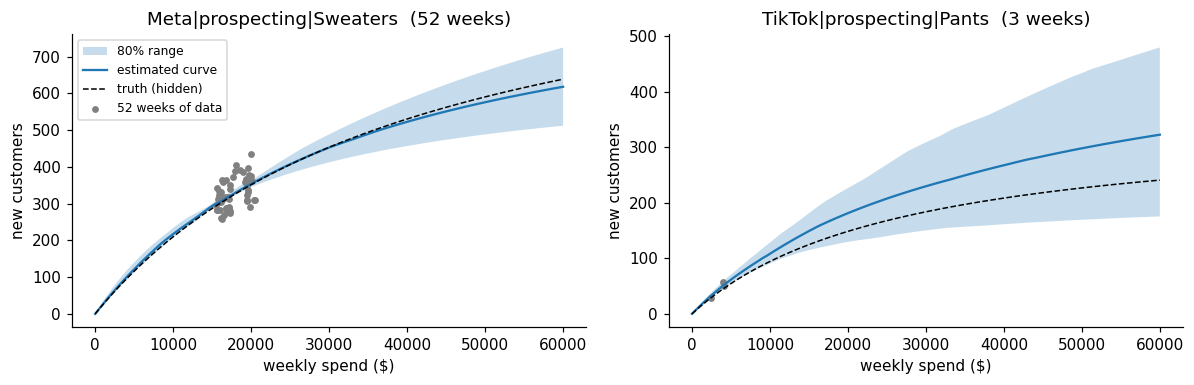

In [8]:
A = np.logspace(np.log10(40), np.log10(4000), 45)
K = np.logspace(np.log10(2000), np.log10(150000), 45)
AA, KK = np.meshgrid(A, K, indexing="ij")
AA, KK = AA.ravel(), KK.ravel()

def posterior(x, y, prior_la, prior_lk, prior_sd):
    """Grid posterior over (a, k) given weekly spend x and customers y."""
    x = np.asarray(x)[:, None]; y = np.asarray(y)[:, None]
    pred = AA[None, :] * x / (KK[None, :] + x)
    sd = 0.12 * pred + 3.0
    ll = (-0.5 * ((y - pred) / sd) ** 2 - np.log(sd)).sum(axis=0) if len(x) else np.zeros(len(AA))
    lp = -0.5 * (((np.log(AA) - prior_la) / prior_sd) ** 2 + ((np.log(KK) - prior_lk) / prior_sd) ** 2)
    w = np.exp(ll + lp - (ll + lp).max())
    return w / w.sum()

def data_for(cell_id, df):
    d = df[(df.cell_id == cell_id) & (df.spend > 0)]
    return d.spend.values, d.customers.values

# pass 1: loose prior to find each group's typical curve; pass 2: prior centred there
group_prior = {}
for (ch, ct), d in cells.groupby(["channel", "ctype"]):
    las, lks = [], []
    for cid in d.cell_id:
        x, y = data_for(cid, hist)
        if len(x) >= 40:
            w = posterior(x, y, np.log(500), np.log(25000), 3.0)
            las.append((w * np.log(AA)).sum()); lks.append((w * np.log(KK)).sum())
    group_prior[(ch, ct)] = (np.mean(las), np.mean(lks))

def build_posteriors(df):
    out = {}
    for _, c in cells.iterrows():
        la, lk = group_prior[(c.channel, c.ctype)]
        x, y = data_for(c.cell_id, df)
        out[c.cell_id] = posterior(x, y, la, lk, 0.7 if len(x) >= 20 else 1.3)   # less sure a new cell behaves like its group
    return out

post = build_posteriors(hist)

def curve_band(w, xs, n=400, rng_=rng):
    idx = rng_.choice(len(w), size=n, p=w)
    ys = AA[idx][:, None] * xs[None, :] / (KK[idx][:, None] + xs[None, :])
    return np.percentile(ys, [10, 50, 90], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, cid in zip(axes, ["Meta|prospecting|Sweaters", "TikTok|prospecting|Pants"]):
    c = cells[cells.cell_id == cid].iloc[0]
    xs = np.linspace(0, 60000, 120)
    lo_, med_, hi_ = curve_band(post[cid], xs)
    x, y = data_for(cid, hist)
    ax.fill_between(xs, lo_, hi_, alpha=0.25, label="80% range")
    ax.plot(xs, med_, label="estimated curve")
    ax.plot(xs, g(xs, c.a, c.k), "k--", lw=1, label="truth (hidden)")
    ax.scatter(x, y, s=12, color="gray", label=f"{len(x)} weeks of data")
    ax.set_title(f"{cid}  ({len(x)} weeks)"); ax.set_xlabel("weekly spend ($)"); ax.set_ylabel("new customers")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. The weekly allocator (tier 2)

Each week:
1. **Thompson draw**: sample one plausible curve per cell from its posterior.
2. **Bounds**: each cell may move at most 20% from last week. **Inventory comes first**: if even the lower bound would risk running out of stock, spend is cut below the move limit.
3. **Stock as a chance constraint**: using 40 posterior draws, the 90th percentile of a category's demand must stay below what its stock can serve (accepted stockout chance of 10%).
4. **Greedy fill**: spend each $500 step where the next dollar earns the most 12-month contribution, if it clears that category's **payback floor**.
5. **Explore**: a 5% reserve funds the most uncertain eligible cells. Its expected cost versus the best known plan must stay under a **loss cap** (2% of expected contribution). If it does not, the reserve is trimmed and the freed dollars go back through the fill, with test cells capped so they cannot grow back.

In [9]:
STEP, DELTA, EXPLORE = 500, 0.20, 0.05
EPS = 0.10                      # accepted chance of running out of stock
LOSS_CAP = 0.02                 # exploration may give up at most 2% of expected contribution
S = 40                          # posterior draws used for the stock chance and for uncertainty
MIN_WIDTH, ELIG = 0.20, 1.0     # a cell is worth testing if its return is uncertain and its upper bound clears the floor
LAM = cells.category.map({"Sweaters": 1.0, "Shirts": 1.0, "Jackets": 1.1, "Pants": 1.0, "Accessories": 0.9}).values  # payback floor per category (Finance)
CAT, CH = cells.category.values, cells.channel.values
cat_names = list(cust_cap.index)
masks = {c: CAT == c for c in cat_names}

def sample_ab(post, rng_):
    idx = np.array([rng_.choice(len(post[c]), p=post[c]) for c in cells.cell_id])
    return AA[idx], KK[idx]

def stock_draws(post, rng_):
    A_s, K_s = np.zeros((S, len(cells))), np.zeros((S, len(cells)))
    for j, c in enumerate(cells.cell_id):
        idx = rng_.choice(len(post[c]), size=S, p=post[c])
        A_s[:, j], K_s[:, j] = AA[idx], KK[idx]
    return A_s, K_s

def v12_draw(rng_):
    s_draw = cells.s_hat * rng_.lognormal(0, cells.s_se / cells.s_hat)      # share uncertainty carried through
    return (cells.sameday_rev_per_cust / s_draw).values

def cat_demand(x, A_s, K_s, m):
    return g(x[m][None, :], A_s[:, m], K_s[:, m]).sum(axis=1)               # customers in a category, one value per draw

def expected_contrib(x, ctx):
    return (ctx["mV"] * g(x[None, :], ctx["A_s"], ctx["K_s"]).mean(axis=0)).sum()

def allocate(post, prev, seed, explore_scale=1.0):
    rng_ = np.random.default_rng(seed)
    a, k = sample_ab(post, rng_)                         # Thompson draw: one plausible curve per cell
    A_s, K_s = stock_draws(post, rng_)                   # more draws, used for the stock chance and for exploration
    mV = cells.margin.values * v12_draw(rng_)
    hi = np.maximum((1 + DELTA) * prev, np.where(prev < 1, 1500, 0))        # a brand-new cell may start a test
    x = (1 - DELTA) * prev
    for c in cat_names:                                  # inventory beats the move limit
        while np.quantile(cat_demand(x, A_s, K_s, masks[c]), 1 - EPS) > cust_cap[c]:
            x[masks[c]] *= 0.97
    left = {ch: weekly_budget[ch] - x[CH == ch].sum() for ch in weekly_budget}
    dem = {c: cat_demand(x, A_s, K_s, masks[c]) for c in cat_names}
    tested = np.zeros(len(cells), bool)

    if explore_scale > 0:                                # explicit reserve, ranked by value of information
        marg = A_s * K_s / (K_s + 2 * prev[None, :] + 1) ** 2 * mV[None, :]  # marginal $ per $ at a test spend of 2x, one row per draw
        upper, width = np.percentile(marg, 90, axis=0), marg.std(axis=0) / (marg.mean(axis=0) + 1e-9)
        for ch in weekly_budget:
            m = np.where(CH == ch)[0]
            elig = [i for i in m[np.argsort(-width[m])] if upper[i] >= ELIG * LAM[i] and width[i] > MIN_WIDTH][:3]
            for i in elig:
                put = min(EXPLORE * explore_scale * weekly_budget[ch] / len(elig), hi[i] - x[i], left[ch])
                if put <= 0: continue
                trial = dem[CAT[i]] + g(x[i] + put, A_s[:, i], K_s[:, i]) - g(x[i], A_s[:, i], K_s[:, i])
                if np.quantile(trial, 1 - EPS) <= cust_cap[CAT[i]]:
                    dem[CAT[i]] = trial; x[i] += put; left[ch] -= put; tested[i] = True
        hi = np.where(tested, np.minimum(hi, x), hi)     # test spend is fixed: the fill cannot grow it back

    while True:                                          # greedy fill across all channels
        val = mV * (g(x + STEP, a, k) - g(x, a, k)) / STEP                   # 12-month contribution per dollar
        room = np.array([left[ch] >= STEP for ch in CH]) & (x + STEP <= hi)
        ok = room & (val >= LAM)                                             # payback floor
        chosen = None
        for i in np.argsort(-np.where(ok, val, -1)):
            if not ok[i]: break
            trial = dem[CAT[i]] + g(x[i] + STEP, A_s[:, i], K_s[:, i]) - g(x[i], A_s[:, i], K_s[:, i])
            if np.quantile(trial, 1 - EPS) <= cust_cap[CAT[i]]:              # stock chance limit
                chosen, dem[CAT[i]] = i, trial; break
        if chosen is None: break
        x[chosen] += STEP; left[CH[chosen]] -= STEP
    return x, tested, left, dict(A_s=A_s, K_s=K_s, mV=mV, dem=dem)

def expected_net(x, ctx):
    return expected_contrib(x, ctx) - x.sum()                                # expected 12-month contribution minus the ad spend

def plan_week(post, prev, seed):
    x0, _, _, ctx0 = allocate(post, prev, seed, explore_scale=0)             # best known plan, no exploration
    base_net, scale_ref = expected_net(x0, ctx0), expected_contrib(x0, ctx0)
    scale = 1.0
    x, tested, left, ctx = allocate(post, prev, seed, explore_scale=scale)
    cost = base_net - expected_net(x, ctx)                                   # what exploring is expected to give up, net of spend
    while cost > LOSS_CAP * scale_ref and scale > 0.01:                      # trim the reserve until the loss cap holds
        scale *= 0.5
        x, tested, left, ctx = allocate(post, prev, seed, explore_scale=scale)
        cost = base_net - expected_net(x, ctx)
    if cost > LOSS_CAP * scale_ref:                                          # cannot be afforded at all this week
        scale = 0.0
        x, tested, left, ctx = allocate(post, prev, seed, explore_scale=0)
        cost = 0.0
    return x, tested, left, ctx, dict(explore_cost_pct=100 * cost / scale_ref, reserve_scale=scale)

x_new, tested, left, ctx, info = plan_week(post, prev_spend, 11)
print("Unspent by channel:", {k_: int(v) for k_, v in left.items()})
print(f"Exploration: reserve scale {info['reserve_scale']:.2f} (1.00 = full 5%), expected cost {info['explore_cost_pct']:.2f}% of contribution (cap {LOSS_CAP*100:.0f}%), {int(tested.sum())} test cells")

Unspent by channel: {'Meta': 47877, 'Google': 38721, 'TikTok': 451, 'Pinterest': 7412}
Exploration: reserve scale 1.00 (1.00 = full 5%), expected cost -0.04% of contribution (cap 2%), 2 test cells


## 8. What it recommends this week, and why

A manager sees each move with the evidence and the reason. Below, the cells that change most, and then the stock check.

In [10]:
rec = cells[["cell_id", "channel", "ctype", "category"]].copy()
rec["last_week_$"] = prev_spend.round(0)
rec["recommended_$"] = x_new.round(0)
rec["change_%"] = ((x_new / prev_spend - 1) * 100).round(0)
A_s, K_s = ctx["A_s"], ctx["K_s"]
marg_draws = A_s * K_s / (K_s + x_new[None, :]) ** 2 * ctx["mV"][None, :]
rec["est_marginal_$_per_$"] = marg_draws.mean(axis=0).round(2)
rec["payback_floor"] = LAM
def reason(r, i):
    if tested[i]: return "test: uncertain, funded from the reserve"
    if r["change_%"] < -21: return "cut: stock limit overrides the 20% move limit"
    if r["change_%"] <= -19: return "cut: next dollar earns below the payback floor"
    if r["change_%"] >= 19: return "increase: next dollar earns above the floor"
    return "hold / small move"
rec["why"] = [reason(r, i) for i, r in rec.iterrows()]
big = rec.reindex(rec["change_%"].abs().sort_values(ascending=False).index).head(10).drop(columns=["cell_id"])
print(big.to_string(index=False))
stock_tbl = pd.DataFrame({c: {"demand_p90": np.quantile(ctx["dem"][c], 0.9), "demand_mean": ctx["dem"][c].mean(), "stock_cap": cust_cap[c]} for c in cat_names}).round(0).astype(int)
print("\nStock check (customers per week; the 90th percentile must stay under the cap):")
print(stock_tbl.to_string())

  channel       ctype    category  last_week_$  recommended_$  change_%  est_marginal_$_per_$  payback_floor                                            why
     Meta prospecting     Jackets       5501.0         1188.0     -78.0                  1.65            1.1  cut: stock limit overrides the 20% move limit
     Meta         DPA     Jackets      33667.0         7269.0     -78.0                  1.14            1.1  cut: stock limit overrides the 20% move limit
   Google prospecting     Jackets       2999.0          647.0     -78.0                  1.15            1.1  cut: stock limit overrides the 20% move limit
Pinterest prospecting     Jackets       4130.0          892.0     -78.0                  0.83            1.1  cut: stock limit overrides the 20% move limit
   TikTok prospecting     Jackets       3342.0          721.0     -78.0                  1.37            1.1  cut: stock limit overrides the 20% move limit
   Google    shopping     Jackets      29320.0         6330.0   

## 9. Head to head: 26 simulated weeks

Both policies start from the same spend and face the same random noise and the same stock caps. The hidden truth decides the outcome.

- **Current loop:** move toward last week's same-day ROAS, ignore stock.
- **New approach:** learn curves from what it observes (refit every 4 weeks), then plan the week with the steps above.

Outcomes: 12-month contribution from the customers actually served after stock limits, minus ad spend.

In [11]:
T = 26
sim_rng = np.random.default_rng(2024)
noise_c = sim_rng.lognormal(0, 0.10, (T, len(cells)))
noise_r = sim_rng.lognormal(0, 0.05, (T, len(cells)))

def outcome(spend_vec, t):
    """True customers served (after stock), plus noisy observations a planner would see."""
    true_c = g(spend_vec, cells.a.values, cells.k.values)
    served = true_c.copy(); waste = np.zeros(len(cells))
    for c in cat_names:
        m = masks[c]
        if true_c[m].sum() > cust_cap[c]:
            f = cust_cap[c] / true_c[m].sum()
            served[m] = true_c[m] * f; waste[m] = spend_vec[m] * (1 - f)
    obs_c = served * noise_c[t]
    obs_rev = obs_c * cells.V12.values * cells.s.values * noise_r[t]
    contrib = (served * cells.V12.values * cells.margin.values).sum()
    return contrib, waste.sum(), obs_c, obs_rev

res = {"current loop": [], "new approach": []}
spend_a, spend_b = prev_spend.copy(), prev_spend.copy()
data_b = hist[["week", "cell_id", "spend", "customers"]].copy()
post_b = post
trims = []
for t in range(T):
    contrib_a, waste_a, obs_c_a, obs_rev_a = outcome(spend_a, t)
    res["current loop"].append(dict(week=t + 1, spend=spend_a.sum(), contribution=contrib_a, wasted_on_stockouts=waste_a))
    spend_a = current_loop_step(spend_a, np.where(spend_a > 0, obs_rev_a / np.maximum(spend_a, 1), TARGET))
    spend_b, _, _, _, info_t = plan_week(post_b, spend_b, 1000 + t)
    trims.append(info_t)
    contrib_b, waste_b, obs_c_b, _ = outcome(spend_b, t)
    res["new approach"].append(dict(week=t + 1, spend=spend_b.sum(), contribution=contrib_b, wasted_on_stockouts=waste_b))
    data_b = pd.concat([data_b, pd.DataFrame(dict(week=t, cell_id=cells.cell_id, spend=spend_b, customers=obs_c_b))], ignore_index=True)
    if t % 4 == 3:
        post_b = build_posteriors(data_b)

df_a, df_b = pd.DataFrame(res["current loop"]), pd.DataFrame(res["new approach"])
tot = pd.DataFrame({"current loop": df_a[["spend", "contribution", "wasted_on_stockouts"]].sum(),
                    "new approach": df_b[["spend", "contribution", "wasted_on_stockouts"]].sum()}).T
tot["net_profit"] = tot.contribution - tot.spend
tot["contribution_per_dollar"] = tot.contribution / tot.spend
print((tot / 1e6).round(2).drop(columns="contribution_per_dollar").rename(columns=lambda c: c + " ($M)").to_string())
print("\nContribution per ad dollar:", tot.contribution_per_dollar.round(2).to_dict())
print(f"The new approach spends {tot.loc['new approach','spend']/tot.loc['current loop','spend']*100:.0f}% as much, because it declines dollars that would not pay back.")
diff = tot.loc["new approach", "net_profit"] - tot.loc["current loop", "net_profit"]
print(f"Net profit difference over {T} weeks: {diff/1e6:+.2f} $M  (synthetic data, built to contain these problems)")
print(f"Exploration: trimmed in {sum(t['reserve_scale'] < 1 for t in trims)} of {T} weeks, average cost {np.mean([t['explore_cost_pct'] for t in trims]):.2f}% of contribution (cap {LOSS_CAP*100:.0f}%)")

              spend ($M)  contribution ($M)  wasted_on_stockouts ($M)  net_profit ($M)
current loop        8.45               8.71                       0.7             0.26
new approach        4.48               7.01                       0.0             2.53

Contribution per ad dollar: {'current loop': 1.03, 'new approach': 1.56}
The new approach spends 53% as much, because it declines dollars that would not pay back.
Net profit difference over 26 weeks: +2.27 $M  (synthetic data, built to contain these problems)
Exploration: trimmed in 0 of 26 weeks, average cost 0.01% of contribution (cap 2%)


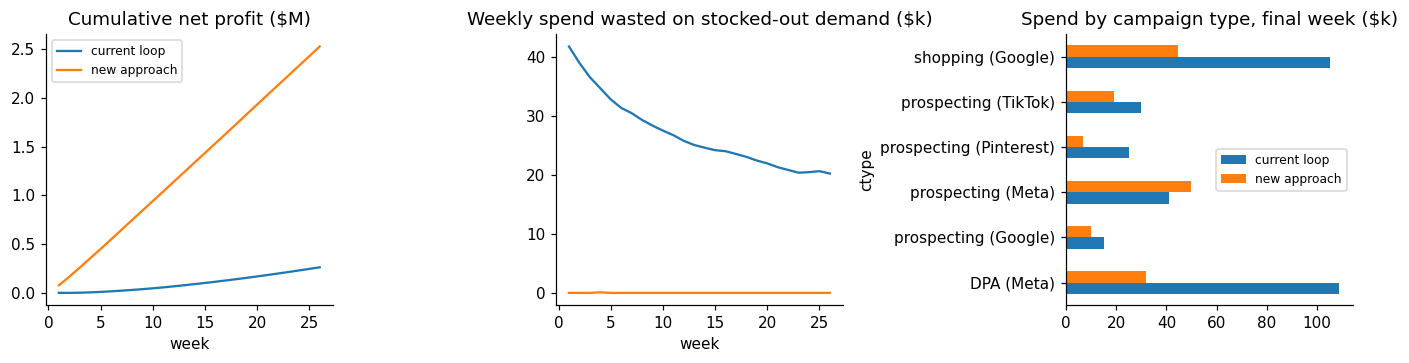

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
axes[0].plot(df_a.week, (df_a.contribution - df_a.spend).cumsum() / 1e6, label="current loop")
axes[0].plot(df_b.week, (df_b.contribution - df_b.spend).cumsum() / 1e6, label="new approach")
axes[0].set_title("Cumulative net profit ($M)"); axes[0].set_xlabel("week"); axes[0].legend(fontsize=8)
axes[1].plot(df_a.week, df_a.wasted_on_stockouts / 1e3, label="current loop")
axes[1].plot(df_b.week, df_b.wasted_on_stockouts / 1e3, label="new approach")
axes[1].set_title("Weekly spend wasted on stocked-out demand ($k)"); axes[1].set_xlabel("week")
by_type = pd.DataFrame({"current loop": spend_a, "new approach": spend_b, "ctype": cells.ctype + " (" + cells.channel + ")"}).groupby("ctype").sum() / 1e3
by_type.plot.barh(ax=axes[2], legend=True); axes[2].set_title("Spend by campaign type, final week ($k)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Stress test: does the exploration loss cap bite?
In the runs above the reserve is small and well chosen, so the cap does not bind. Here the reserve is deliberately set to 40% of each budget, any uncertain cell is allowed, and the cap is a tight 0.1%. The planner should cut the reserve back until the expected cost is under the cap, and the freed dollars go back through the fill.

In [13]:
saved = (EXPLORE, LOSS_CAP, MIN_WIDTH, ELIG)
EXPLORE, LOSS_CAP, MIN_WIDTH, ELIG = 0.40, 0.001, 0.0, 0.0       # big reserve, any uncertain cell is eligible, tight 0.1% cap
x_s, tested_s, left_s, ctx_s, info_s = plan_week(post, prev_spend, 11)
EXPLORE, LOSS_CAP, MIN_WIDTH, ELIG = saved
print(f"Stress test: the planner cut the reserve to {info_s['reserve_scale']:.2f} of its full size, "
      f"so the expected cost is {info_s['explore_cost_pct']:.2f}% of contribution (cap 0.10%), {int(tested_s.sum())} test cells.")

Stress test: the planner cut the reserve to 0.00 of its full size, so the expected cost is 0.00% of contribution (cap 0.10%), 0 test cells.


## 10. Tier 1: when would the system recommend moving money between channels?

The rule: shift a bounded amount from channel A to channel B only when the **probability that B's next dollar earns more than A's** is high (here above 80%), B clears its payback floor, and B can actually spend more (it is not already leaving budget unspent). A human approves. The probability comes from the same posterior draws.

In [14]:
x_ref = x_new
stock_bound = {c: np.quantile(ctx["dem"][c], 0.9) >= 0.97 * cust_cap[c] for c in cat_names}
usable = np.array([not stock_bound[c] for c in CAT])                       # an extra dollar cannot go to a stock-bound category
marg_ch = {}
for ch in weekly_budget:
    m = (CH == ch) & usable
    mg = A_s[:, m] * K_s[:, m] / (K_s[:, m] + x_ref[None, m]) ** 2 * ctx["mV"][None, m]
    marg_ch[ch] = mg.max(axis=1)                                          # an extra envelope dollar goes to the channel's best cell
rows = []
for a_ch in weekly_budget:
    for b_ch in weekly_budget:
        if a_ch == b_ch: continue
        p = float((marg_ch[b_ch] > marg_ch[a_ch]).mean())
        floor_b = float(LAM[CH == b_ch].mean())
        can_spend = left[b_ch] < 0.05 * weekly_budget[b_ch]                # a channel with unspent budget cannot use more
        act = p > 0.80 and marg_ch[b_ch].mean() >= floor_b and can_spend
        rows.append(dict(move_from=a_ch, move_to=b_ch, prob_B_beats_A=round(p, 2), B_marginal=round(marg_ch[b_ch].mean(), 2), B_can_spend=can_spend,
                         recommend=f"shift 3% of {a_ch}'s envelope (needs approval)" if act else "no change"))
shift = pd.DataFrame(rows).sort_values("prob_B_beats_A", ascending=False)
print("Value of an extra envelope dollar by channel (best usable cell, 12-month contribution per $):",
      {k_: round(float(v.mean()), 2) for k_, v in marg_ch.items()})
print(shift.head(6).to_string(index=False))

Value of an extra envelope dollar by channel (best usable cell, 12-month contribution per $): {'Meta': 1.34, 'Google': 1.32, 'TikTok': 1.1, 'Pinterest': 0.81}
move_from move_to  prob_B_beats_A  B_marginal  B_can_spend                                         recommend
Pinterest    Meta            1.00        1.34        False                                         no change
Pinterest  Google            1.00        1.32        False                                         no change
Pinterest  TikTok            0.97        1.10         True shift 3% of Pinterest's envelope (needs approval)
   TikTok  Google            0.95        1.32        False                                         no change
   TikTok    Meta            0.95        1.34        False                                         no change
     Meta  Google            0.57        1.32        False                                         no change


## 11. Weekly envelope: how the monthly budget becomes this week's budget

A flat monthly / 4.3 would ignore both the demand shape and what is already spent. The weekly envelope is the monthly envelope left to spend, times this week's demand weight, divided by the weights of the remaining weeks. Underspend rolls forward and the monthly total is never exceeded.

In [15]:
def weekly_envelope(monthly, spent, weights, i):
    return (monthly - spent) * weights[i] / np.sum(weights[i:])

monthly, weights = 200_000, np.array([1.0, 1.2, 1.0, 0.9, 0.3])      # last week of the month is partial
spent, rows = 0.0, []
actual = [38_000, None, None, None, None]                              # week 1 underspends (a stock cap bound)
for i in range(len(weights)):
    env = weekly_envelope(monthly, spent, weights, i)
    used = actual[i] if actual[i] is not None else env
    rows.append(dict(week=i + 1, weight=weights[i], envelope=round(env), spent=round(used), flat_split=round(monthly / weights.size)))
    spent += used
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nTotal spent: ${spent:,.0f} of ${monthly:,} (never above the monthly envelope). Week 1's underspend was spread over the remaining weeks.")

 week  weight  envelope  spent  flat_split
    1     1.0     45455  38000       40000
    2     1.2     57176  57176       40000
    3     1.0     47647  47647       40000
    4     0.9     42882  42882       40000
    5     0.3     14294  14294       40000

Total spent: $200,000 of $200,000 (never above the monthly envelope). Week 1's underspend was spread over the remaining weeks.


## 12. Tier 3: daily pacing inside the week

Tier 3 splits one cell's weekly budget across days and ad sets. It never moves money between cells. It uses:
- **Weekday demand weights**: today's share is today's weight divided by the weights of the remaining days.
- **A 10% daily move limit**, measured against yesterday's spend scaled to today's weight.
- **Hold-steady rules**: ad sets in a learning phase, or with too little data after a few days, are held. **New ad sets start from a test allowance, not zero.**
- **Budget and stock win**: if holds and minimums add up to more than today's budget, everything is scaled down.
- **Stock paced like budget**: today's stock allowance is the remaining cap times today's share, and it caps the whole envelope.

In [16]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
w = np.array([1.0, 0.9, 0.9, 1.0, 1.2, 1.5, 1.3])                      # weekday demand weights (from historical sessions)
CELL = "Meta|prospecting|Sweaters"
ci = int(cells.index[cells.cell_id == CELL][0])
weekly = float(x_new[ci])                                              # this cell's weekly budget from tier 2
size = np.array([0.30, 0.25, 0.20, 0.12, 0.08, 0.05]); eff = np.array([1.15, 1.00, 0.90, 1.05, 1.00, 0.95])
ads = pd.DataFrame({"adset": [f"A{j+1}" for j in range(6)], "size": size, "eff": eff,
                    "days_live": [200, 200, 150, 90, 2, 40], "conv7": [60, 45, 30, 14, 0, 3],
                    "learning": [False, False, False, False, True, False]})
ads["yesterday"] = weekly / 7 * ads["size"]                            # last Sunday's spend before the week starts
ads.loc[ads.adset == "A5", "yesterday"] = 0.0                          # brand new ad set: no history
MIN_CONV, NEW_DAYS, TEST_ALLOW, DDAY, DSTEP = 10, 3, 400.0, 0.10, 25.0
pa, pk = (post[CELL] * AA).sum(), (post[CELL] * KK).sum()               # the cell's estimated curve, shared by its ad sets
mV_cell = float(ctx["mV"][ci]); lam_cell = float(LAM[ci])

def pace_day(d, spent, cap_remaining, prev_day):
    share = w[d] / w[d:].sum()
    cap_today = cap_remaining * share                                   # dollar stock allowance for today, shared by all ad sets
    budget = min((weekly - spent) * share, cap_today)
    base = np.maximum(prev_day * w[d] / w[d - 1], np.where(ads.days_live < 5, TEST_ALLOW, 0))   # new ad sets start from a test allowance
    thin = (ads.learning | ((ads.conv7 < MIN_CONV) & (ads.days_live > NEW_DAYS))).values
    x = np.where(thin, np.minimum(base, cap_today), 0.0)                # held steady
    free = ~thin
    hi = np.minimum((1 + DDAY) * base, cap_today)
    need = (1 - DDAY) * base
    x[free] = np.minimum(need, hi)[free]
    if x.sum() > budget:                                                # budget or stock allowance wins over move limits
        x = x * budget / x.sum()
    left = max(budget - x.sum(), 0.0)
    a_j, k_j = pa * ads["size"].values * ads["eff"].values, pk * ads["size"].values
    while left >= DSTEP:                                                # greedy fill, per-dollar value of the next step
        dq = (g(7 * (x + DSTEP), a_j, k_j) - g(7 * x, a_j, k_j)) / 7
        val = mV_cell * dq / DSTEP
        ok = free & (x + DSTEP <= hi) & (val >= lam_cell)
        if not ok.any(): break
        j = int(np.argmax(np.where(ok, val, -1)))
        x[j] += DSTEP; left -= DSTEP
    return x, budget, share, thin

def run_week(cap_remaining):
    spent, prev, rows, alloc = 0.0, ads.yesterday.values.copy(), [], []
    for d in range(7):
        x, budget, share, thin = pace_day(d, spent, cap_remaining - spent, prev)
        spent += x.sum(); prev = x
        rows.append(dict(day=days[d], share_of_remaining=round(share, 2), day_budget=round(budget), spent=round(x.sum())))
        alloc.append(dict(day=days[d], **{a: round(v) for a, v in zip(ads.adset, x)}))
    return pd.DataFrame(rows), pd.DataFrame(alloc), spent

print(f"Weekly budget for {CELL}: ${weekly:,.0f}   (even split would be ${weekly/7:,.0f} a day)\n")
sched, alloc, spent = run_week(cap_remaining=3 * weekly)
print(sched.to_string(index=False))
print("\nSpend by ad set (A5 is new and in a learning phase, so it starts from a test allowance and is held, A6 has too little data and is held; A1 to A4 are moved by the fill):")
print(alloc.to_string(index=False))
print(f"\nSpent ${spent:,.0f} of ${weekly:,.0f}. Money stays inside this cell and follows the weekday shape.")

Weekly budget for Meta|prospecting|Sweaters: $18,277   (even split would be $2,611 a day)

day  share_of_remaining  day_budget  spent
Mon                0.13        2343   2323
Tue                0.13        2112   2092
Wed                0.15        2115   2107
Thu                0.20        2351   2336
Fri                0.30        2826   2813
Sat                0.54        3539   3522
Sun                1.00        3085   3068

Spend by ad set (A5 is new and in a learning phase, so it starts from a test allowance and is held, A6 has too little data and is held; A1 to A4 are moved by the fill):
day   A1  A2  A3  A4  A5  A6
Mon  642 552 387 242 400 100
Tue  620 447 313 221 400  90
Wed  658 452 282 224 400  90
Thu  733 502 307 249 444 100
Fri  867 593 381 319 533 121
Sat 1075 742 504 384 667 151
Sun  939 653 443 324 578 131

Spent $18,260 of $18,277. Money stays inside this cell and follows the weekday shape.


In [17]:
tight, alloc_t, spent_t = run_week(cap_remaining=0.6 * weekly)       # stock only supports 60% of the weekly budget
print(f"Same week with a tight stock allowance (only ${0.6*weekly:,.0f} of spend is safe):")
print(tight.to_string(index=False))
print(f"\nSpent ${spent_t:,.0f}. Stock pacing caps each day's budget (and scales holds down), so the stock lasts all week and the rest is reported as unspent.")

Same week with a tight stock allowance (only $10,966 of spend is safe):
day  share_of_remaining  day_budget  spent
Mon                0.13        1406   1406
Tue                0.13        1265   1265
Wed                0.15        1265   1251
Thu                0.20        1409   1402
Fri                0.30        1693   1675
Sat                0.54        2125   2111
Sun                1.00        1856   1838

Spent $10,948. Stock pacing caps each day's budget (and scales holds down), so the stock lasts all week and the rest is reported as unspent.


## 13. What this demo covers, and what it does not

| Idea in the document | In this notebook |
| --- | --- |
| Value customers at 12 months (same-day revenue / same-day share), share uncertainty carried | Yes, by channel and campaign type. Not by category or segment, no shrinkage toward parent, not net of retention marketing cost |
| Reconcile sources, tests anchor the rest | Yes, as bias correction against tests. Correlated errors are not modeled |
| Saturating response curves, partial pooling, uncertainty | Yes (grid posterior, prior by channel and type). Adstock, creative age and seasonality are not simulated |
| Thompson draw each week | Yes |
| Exploration reserve ranked by value of information, with holdouts | Reserve and ranking: yes. Holdouts and measuring lift: not simulated |
| Exploration loss cap and trimming, test spend cannot grow back | Yes |
| Greedy fill, payback floor per category | Yes |
| Stock as a chance constraint, inventory overrides the move limit | Yes (posterior draws, 10% accepted chance). Replenishment and baseline demand are folded into one weekly customer cap. Sub-department level and a sell-through bonus are not included |
| 20% weekly move limit, channel envelopes, money never crosses channels | Yes |
| Weekly envelope from the monthly envelope with rollover | Yes |
| Tier 1 rule: shift only when the probability is high | Yes (probability from posterior draws, 3% example shift, human approval) |
| Tier 3: weekday weights, 10% daily limit, hold-steady rules, test allowance for new ad sets, stock paced | Yes, for one cell and one week |
| Human approval, overrides, shadow mode, routing, stale-feed guardrails, kill switch | Not simulated (operational design) |
| Controlled test against the manual process, rollback triggers | Not simulated. The head-to-head above uses the hidden truth, which a real test would have to estimate |

**Take-away:** the mechanics in the document hold together in a runnable form. The numbers are synthetic, so they show how the pieces interact, not what Quince would earn.